# State Space and Frequency Domain

This notebook gives two complementary views of time series: latent-state filtering in the time domain ([state-space models](../../notes/time_series/state_space_models.md)) and periodic structure in the frequency domain ([frequency-domain analysis](../../notes/time_series/frequency_domain_analysis.md)).

Local-level model:

$$
\mu_t=\mu_{t-1}+\eta_t,\quad \eta_t\sim N(0,Q),\qquad y_t=\mu_t+\varepsilon_t,\quad \varepsilon_t\sim N(0,R).
$$

## 1. One Kalman update by hand

With prediction $a_{t|t-1}=10$, $P_{t|t-1}=1.25$, observation $y_t=12$, and $R=1$, the note gives $v=2$, $F=2.25$, $K=0.5556$, $a_{t|t}=11.111$, $P_{t|t}=0.5556$. Check, and see how $R$ changes the gain.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import periodogram

def update(a, P, y, R):
    v, F = y - a, P + R
    K = P / F
    return v, F, K, a + K * v, (1 - K) * P

for R in (0.1, 1, 4):
    v, F, K, a_new, P_new = update(10, 1.25, 12, R)
    print(f'R={R:>4}: v={v}, F={F:.3f}, K={K:.4f}, a={a_new:.4f}, P={P_new:.4f}')

R= 0.1: v=2, F=1.350, K=0.9259, a=11.8519, P=0.0926
R=   1: v=2, F=2.250, K=0.5556, a=11.1111, P=0.5556
R=   4: v=2, F=5.250, K=0.2381, a=10.4762, P=0.9524


A noisier measurement (larger $R$) gives a smaller gain, so the updated level stays closer to the prior prediction and the posterior variance stays larger.

## 2. Filter a simulated local level

We simulate a latent random walk observed with noise, run the filter with the true $Q,R$, and compare errors with the raw observations.

In [2]:
rng = np.random.default_rng(21)
n = 120
q, r = 0.08, 0.8
state = np.zeros(n)
for t in range(1, n):
    state[t] = state[t - 1] + rng.normal(scale=np.sqrt(q))
observation = state + rng.normal(scale=np.sqrt(r), size=n)

filtered = np.zeros(n); P_filt = np.zeros(n)
a, P = 0.0, 1.0
for t, y_t in enumerate(observation):
    a_pred, P_pred = a, P + q
    F = P_pred + r
    K = P_pred / F
    a = a_pred + K * (y_t - a_pred)
    P = (1 - K) * P_pred
    filtered[t], P_filt[t] = a, P
print('Observation RMSE:', round(float(np.sqrt(np.mean((observation - state) ** 2))), 3))
print('Filtered RMSE   :', round(float(np.sqrt(np.mean((filtered - state) ** 2))), 3))
Pp = (q + np.sqrt(q * q + 4 * q * r)) / 2
print('steady-state gain:', round(Pp / (Pp + r), 3), ' final P_t|t:', round(P_filt[-1], 3))

Observation RMSE: 0.82
Filtered RMSE   : 0.467
steady-state gain: 0.27  final P_t|t: 0.216


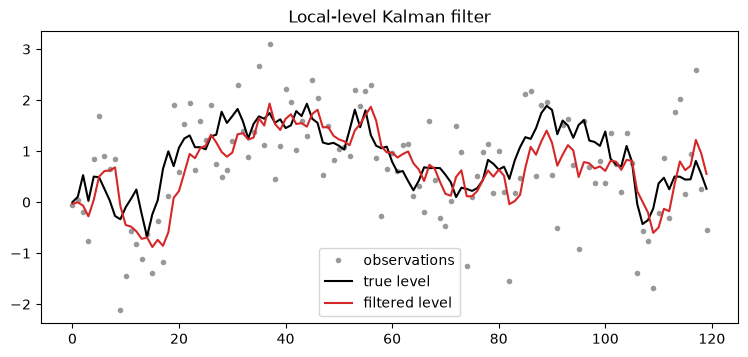

In [3]:
plt.figure(figsize=(9, 3.8))
plt.plot(observation, '.', color='0.6', label='observations')
plt.plot(state, color='k', label='true level')
plt.plot(filtered, color='C3', label='filtered level')
plt.legend(); plt.title('Local-level Kalman filter'); plt.show()

The filtered level has a clearly smaller error than the observations. With $Q/R=0.1$ the steady-state gain is about $0.27$, so each new observation moves the estimate by roughly a quarter of the surprise.

## 3. Missing data

With a missing observation there is no update: the level stays flat and the variance grows by $Q$ at each step, then falls when data return.

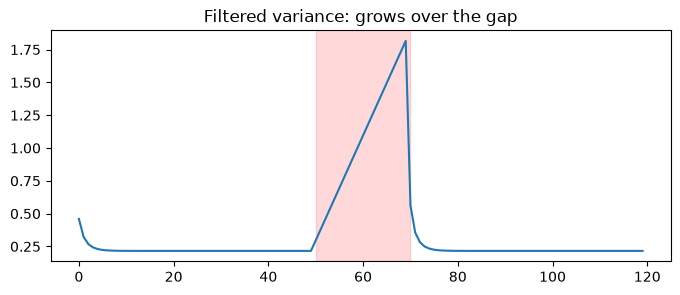

variance before gap: 0.216  end of gap: 1.816  after: 0.216


In [4]:
obs = observation.copy()
miss = np.zeros(n, bool); miss[50:70] = True
a, P = 0.0, 1.0
var_path = np.zeros(n)
for t in range(n):
    P += q
    if not miss[t]:
        K = P / (P + r)
        a += K * (obs[t] - a)
        P *= 1 - K
    var_path[t] = P
plt.figure(figsize=(8, 3)); plt.plot(var_path); plt.axvspan(50, 70, color='r', alpha=.15)
plt.title('Filtered variance: grows over the gap'); plt.show()
print('variance before gap:', round(var_path[49], 3), ' end of gap:', round(var_path[69], 3), ' after:', round(var_path[85], 3))

## 4. Frequency domain: recovering periods

A series with periods 12 and 30 plus noise should show two spectral peaks. With $n=360$ observations the Fourier spacing is $1/360$ and both $1/12$ and $1/30$ are exact bins.

[(0.0833, 12.0), (0.0333, 30.0)]


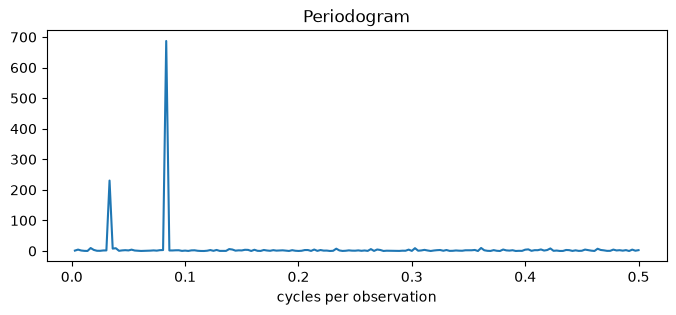

In [5]:
rng = np.random.default_rng(9)
n2 = 360
t = np.arange(n2)
series = 2 * np.sin(2 * np.pi * t / 12) + 1.2 * np.sin(2 * np.pi * t / 30) + rng.normal(size=n2)
frequency, power = periodogram(series, detrend='linear')
mask = frequency > 0
frequency, power = frequency[mask], power[mask]
top = np.argsort(power)[-2:][::-1]
print([(round(float(frequency[i]), 4), round(float(1 / frequency[i]), 2)) for i in top])
plt.figure(figsize=(8, 3)); plt.plot(frequency, power); plt.xlabel('cycles per observation'); plt.title('Periodogram'); plt.show()

The two largest peaks correspond to periods $12$ and $30$. The Kalman filter recursively estimates a latent state, while the periodogram looks for variance concentrated at recurring frequencies; a periodic signal can itself be put into a state-space model through seasonal states.

## 5. Aliasing

Sampling at 1 observation per unit, a cycle of period $1/0.9\approx1.11$ (frequency $0.9$, above the Nyquist limit $0.5$) is indistinguishable from frequency $0.1$ (period 10).

In [6]:
tt = np.arange(40)
hi = np.cos(2 * np.pi * 0.9 * tt)
lo = np.cos(2 * np.pi * 0.1 * tt)
print('max |difference| between 0.9 and 0.1 cycles/obs samples:', float(np.max(np.abs(hi - lo))))
f, p = periodogram(hi)
print('apparent peak frequency:', round(float(f[np.argmax(p)]), 3))

max |difference| between 0.9 and 0.1 cycles/obs samples: 2.0039525594484076e-14
apparent peak frequency: 0.1
